# ➡️ **Multiclass Classification In SVM**

## 0️⃣ Quick Context: Where SVM Fits in Data Science 🧠

Before jumping into **multiclass SVM**, remember:

- **SVM (Support Vector Machine)** is fundamentally a **binary classifier**
- Real-world problems are often **multiclass** (3, 4, 10, 100+ classes)
- Hence, **multiclass SVM = clever combination of multiple binary SVMs**

So the key question becomes:

> ❓ *How do we use a binary classifier to solve a multiclass problem?*

That is exactly what this topic answers.


## 1️⃣ Recap: Binary SVM (Very Important Foundation) 🔁

### 1.1 What Binary SVM Does

Binary SVM tries to find:

- A **hyperplane** that separates two classes
- With **maximum margin**

Mathematically, the decision function is:

$f(x) = w^T x + b$

**Prediction rule:**
- If $f(x) \ge 0$ → Class +1
- If $f(x) < 0$ → Class −1

---

### 1.2 Why SVM is Powerful

- Uses only **support vectors** (critical boundary points)
- Works well in **high-dimensional spaces**
- Kernel trick allows **non-linear decision boundaries**

⚠️ But still: **only two classes at a time**


# 2️⃣ The Core Problem: Why Multiclass is Non-Trivial ❗

Suppose you have:

- Classes: `{A, B, C}`

- Standard SVM can only handle **binary classification**, so it can only learn decision boundaries between **two classes at a time**, such as:
  - A vs B
  - B vs C
  - A vs C  
  *(but not all three classes together in a single model)*

Because of this limitation, a direct multiclass classification is **not possible** using a plain SVM.

👉 Therefore, we need **special strategies** to extend SVM for multiclass classification.


## 3️⃣ Main Strategies for Multiclass SVM 🧩

There are **three major approaches** used to handle multiclass classification with SVM:

1. **One-vs-Rest (OvR / OvA)**  
   - Each class is trained against all remaining classes combined.

2. **One-vs-One (OvO)**  
   - Every pair of classes is trained separately.

3. **Direct Multiclass SVM (Structured / Optimization-based)**  
   - The multiclass problem is solved using a single unified optimization formulation.

Each of these strategies has its own advantages, limitations, and use cases, which we study in detail.


## 4️⃣ One-vs-Rest (OvR / OvA) Strategy 🥇

**Fig: Shows OVR**<br>
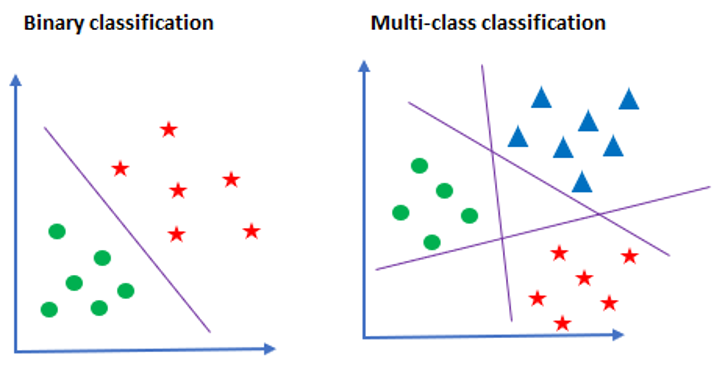

### 4.1 Core Idea Of OVR

For **K classes**, train **K binary SVM classifiers**.

Each classifier:

- Treats **one class as positive**
- Treats **all remaining classes as negative**

#### Example for 3 classes (A, B, C)

| Classifier | Positive | Negative |
|-----------|----------|----------|
| SVM₁ | A | B, C |
| SVM₂ | B | A, C |
| SVM₃ | C | A, B |

---

### 4.2 Prediction Mechanism

For a new data point $x$:

1. Compute decision scores from each classifier:
   - $f_1(x)$, $f_2(x)$, $f_3(x)$

2. Choose the class corresponding to the **maximum score**:
   - $\max_k f_k(x)$

👉 **Highest confidence score wins**

---

### 4.3 Advantages ✅

- Simple and intuitive to understand
- Faster to train compared to One-vs-One
- Scales well for large datasets
- Default multiclass strategy in **scikit-learn**

---

### 4.4 Disadvantages ❌

- Sensitive to **class imbalance**
- Negative class is often very heterogeneous
- Decision boundaries may conflict
- Scores from different classifiers are not always comparable


## 5️⃣ One-vs-One (OvO) Strategy 🥈

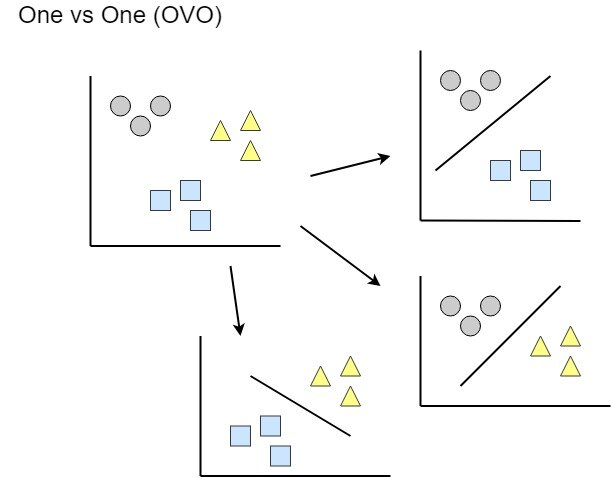

### 5.1 Core Idea

For **K classes**, train:

$$
\frac{K(K-1)}{2}
$$

binary SVM classifiers.

Each classifier distinguishes **between exactly two classes**.

#### Example for 3 classes (A, B, C)

| Classifier | Classes |
|-----------|---------|
| SVM₁ | A vs B |
| SVM₂ | A vs C |
| SVM₃ | B vs C |

---

### 5.2 Prediction Mechanism (Voting System 🗳️)

For a new data point:

- Each binary classifier casts **one vote**
- The class receiving the **maximum number of votes** is predicted

#### Example

- A → 2 votes  
- B → 1 vote  
- C → 0 votes  

➡️ Final Prediction: **Class A**

---

### 5.3 Advantages ✅

- Each classifier is trained on a simpler, balanced dataset
- Less affected by class imbalance
- Often achieves **higher accuracy**
- Works extremely well with **non-linear kernels** (RBF, Polynomial)

---

### 5.4 Disadvantages ❌

- Number of models grows rapidly with number of classes
- Slower prediction for large K
- Higher memory and computation requirements


## 6️⃣ Direct (Native) Multiclass SVM 🧠⚙️

This approach modifies the **optimization problem itself** instead of combining multiple binary classifiers.


### 6.1 Core Idea

Instead of training many binary classifiers:

- Learn **multiple weight vectors**, one for each class
- Optimize a **single unified objective function**

General idea:

$$
\arg\min_{W} \sum_i \max(0, 1 - (w_{y_i}^T x_i - w_k^T x_i))
$$

This formulation is used in:

- **Crammer–Singer SVM**
- Structural SVMs


### 6.2 Characteristics

- Theoretically elegant
- Harder to implement
- Less flexible with kernels
- Not the default choice in most libraries

In **scikit-learn**, this can be accessed using:

`decision_function_shape='crammer_singer'`


## 7️⃣ Role of Kernels in Multiclass SVM 🌐

Kernels behave **exactly the same** as in binary SVM.

Common kernels include:

- Linear
- Polynomial
- RBF (Gaussian)
- Sigmoid

The multiclass strategy only determines:

> How many SVMs are trained  
> How their predictions are combined


## 8️⃣ Mathematical Intuition (High-Level, Not Scary 😄)


### 8.1 OvR Objective

Each binary classifier minimizes:

$$
\frac{1}{2} ||w||^2 + C \sum \xi_i
$$

However, labels are redefined as:

- +1 → target class
- −1 → all remaining classes


### 8.2 OvO Objective

The objective function is the same as binary SVM.

The difference is that training is done only on **two-class subsets** at a time.


## 9️⃣ Evaluation Metrics for Multiclass SVM 📊

Binary classification metrics must be extended for multiclass problems.

Common metrics include:

- Accuracy
- Confusion Matrix (K × K)
- Precision
- Recall
- F1-score

Important averaging methods:

- **Macro** → treats all classes equally
- **Micro** → global performance
- **Weighted** → accounts for class imbalance


## 🔟 Practical Behavior in scikit-learn 🧪

By default:

- `SVC` uses **One-vs-One**
- `LinearSVC` uses **One-vs-Rest**

Reason:

- Non-linear kernels benefit from OvO
- Linear models scale better with OvR


## 1️⃣1️⃣ When to Use Which Strategy 🤔

| Scenario | Best Choice |
|--------|------------|
| Large dataset | One-vs-Rest |
| Few classes with complex boundaries | One-vs-One |
| Class imbalance | One-vs-One |
| High-dimensional sparse data | Linear OvR |
| Theoretical research | Crammer–Singer |


## 1️⃣2️⃣ Common Pitfalls ⚠️

- Forgetting feature scaling
- Using RBF kernel without tuning gamma
- Ignoring class imbalance
- Blindly trusting probability outputs
- Assuming multiclass SVM is a single model


## 1️⃣3️⃣ Summary Mental Model 🧩

> Think of multiclass SVM as a **committee of binary SVMs**  
> Each model votes or scores, and a final decision is made.
